# 03 · Model, ensemble and label-shift correction

**Project 2 · Problem 2 · Part 3.** The task: predict the rating `overall` (1-5) from the review. The metric is **micro F1**, which for single-label multi-class equals accuracy.

This notebook does **not** retrain anything (training takes minutes to hours and is done by the scripts). It loads the saved probabilities of the two models and reproduces every number used in the report:

| Model | How it is trained | Script |
|-------|-------------------|--------|
| **Classical** | TF-IDF (words + word pairs) of `reviewText` and `summary`, plus smoothed average rating of the reviewer and of the product (out-of-fold), logistic regression | `scripts/final_model.py` |
| **Transformer** | `roberta-base` fine-tuned on `summary + review` (GPU) | `scripts/transformer_colab.py` |
| **Ensemble** | log-linear combination, weights fitted on validation A | `scripts/ensemble.py` |

Data split (fixed, stored in `results/model_probabilities/split_indices.npz`): a training pool, **validation A** (20,000 reviews, used to fit weights and calibration) and **validation B** (20,000, only used to judge).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
sys.path.insert(0, str(Path.cwd().parent / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import nnls
from sklearn.metrics import f1_score, confusion_matrix, classification_report

from src import config
import ensemble as ens

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
RESULTS = config.PROJECT_ROOT / "results"

In [2]:
names = ["classical", "transformer"]
probs = {n: np.load(RESULTS / "model_probabilities" / f"{n}_probs.npz") for n in names}
ya, yb = probs["classical"]["ya"], probs["classical"]["yb"]
assert all((probs[n]["ya"] == ya).all() and (probs[n]["yb"] == yb).all() for n in names)
Pa = [probs[n]["Pa"] for n in names]; Pb = [probs[n]["Pb"] for n in names]; Pt = [probs[n]["Pt"] for n in names]
print(f"validation A {len(ya):,} | validation B {len(yb):,} | test {len(Pt[0]):,}")
print("class mix of validation (same as training):", dict(zip(range(1, 6), (np.bincount(ya, minlength=6)[1:] / len(ya)).round(3))))

validation A 20,000 | validation B 20,000 | test 20,000
class mix of validation (same as training): {1: np.float64(0.099), 2: np.float64(0.068), 3: np.float64(0.097), 4: np.float64(0.187), 5: np.float64(0.55)}


## 1 · Each model on its own (validation at the training class mix)
At the training mix 55 % of the reviews are 5-star, so accuracy looks high. Remember that the test set is much more balanced (section 3); these numbers are not the expected test score.

In [3]:
w = ens.fit_weights(Pa, ya)
Pe_a, Pe_b, Pe_t = ens.combine(Pa, w), ens.combine(Pb, w), ens.combine(Pt, w)
print("ensemble weights (log-linear, fitted on validation A):", dict(zip(names, w.round(3))))

truth = np.r_[ya, yb]
sets = {"classical": (Pa[0], Pb[0]), "transformer": (Pa[1], Pb[1]), "ensemble": (Pe_a, Pe_b)}
rows = []
for n, (a, b) in sets.items():
    pred = np.r_[a.argmax(1), b.argmax(1)] + 1
    rows.append({"model": n, "micro F1 (= accuracy)": f1_score(truth, pred, average="micro"),
                 "macro F1": f1_score(truth, pred, average="macro"),
                 "log-loss": ens.nll(ens.LOG(np.r_[a, b]), truth)})
pd.DataFrame(rows).set_index("model").round(4)

ensemble weights (log-linear, fitted on validation A): {'classical': np.float64(0.561), 'transformer': np.float64(0.265)}


,micro F1 (= accuracy),macro F1,log-loss
model,,,
classical,0.7187,0.5642,0.7099
transformer,0.7212,0.5685,0.9122
ensemble,0.7398,0.5863,0.6554


**Note on log-loss.** The transformer has the same accuracy as the classical model but a clearly worse *raw* log-loss (0.91 vs 0.71): its probabilities are over-confident. The ensemble weights (0.56 and 0.27, their sum is below 1) shrink the confidence, and section 4 calibrates it explicitly.

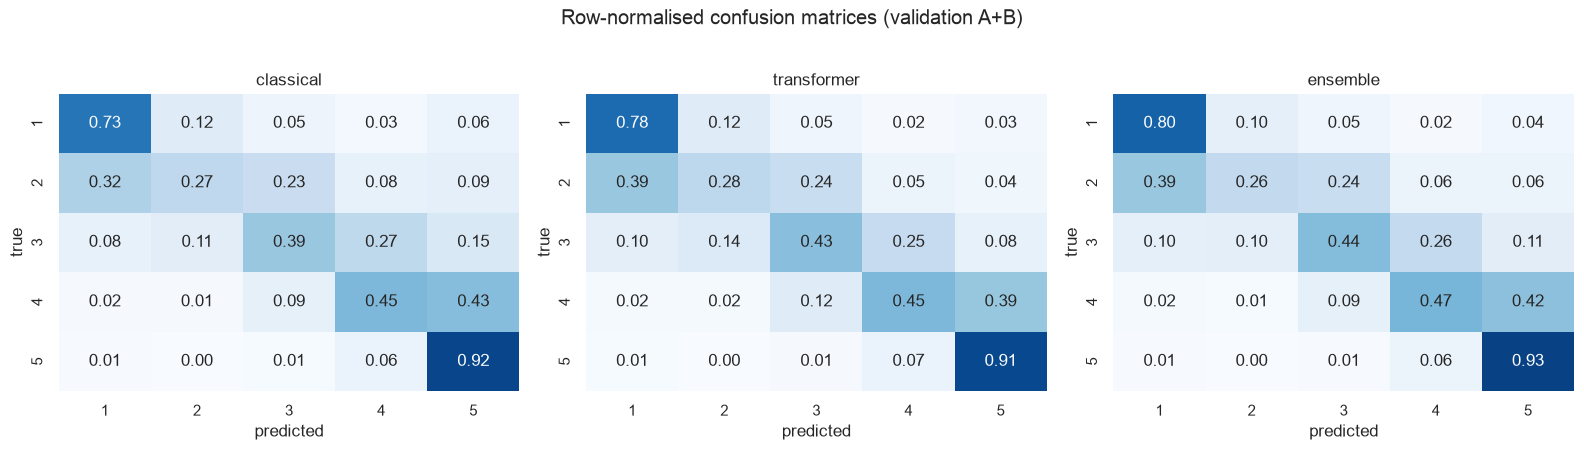

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (n, (a, b)) in zip(axes, sets.items()):
    pred = np.r_[a.argmax(1), b.argmax(1)] + 1
    cm = confusion_matrix(truth, pred, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax, vmin=0, vmax=1,
                xticklabels=range(1, 6), yticklabels=range(1, 6))
    ax.set(title=n, xlabel="predicted", ylabel="true")
plt.suptitle("Row-normalised confusion matrices (validation A+B)", y=1.02)
plt.tight_layout(); plt.show()

**Reading the matrices.** Most mistakes are between neighbouring ratings (2 vs 3, 3 vs 4, 4 vs 5); mistakes across the scale (1 vs 5) are rare. The middle classes are the hard ones, which is why `macro F1` is far below `micro F1` at the training mix.

In [5]:
report = {n: classification_report(truth, np.r_[a.argmax(1), b.argmax(1)] + 1, output_dict=True, zero_division=0)
          for n, (a, b) in sets.items()}
pd.DataFrame({n: {f"F1 of class {k}": report[n][str(k)]["f1-score"] for k in range(1, 6)} for n in sets}).round(3)

,classical,transformer,ensemble
F1 of class 1,0.701,0.697,0.723
F1 of class 2,0.327,0.326,0.328
F1 of class 3,0.427,0.440,0.472
F1 of class 4,0.496,0.501,0.523
F1 of class 5,0.869,0.879,0.885


## 2 · The test set is not like the training set
In `01b_extra_insights` we saw that the words of the test reviews are more negative than in training. Here we estimate the **class mix of the test set** from the model outputs alone (no test labels exist) with two methods:

* **BBSE** (black-box shift estimation): solve `observed predicted mix = confusion matrix of validation A × unknown test mix`.
* **EM with bias-corrected temperature scaling** (Alexandari et al., 2020): calibrate the probabilities on validation A, then run the Saerens EM algorithm on the test probabilities.

Both assume that only the class mix changed, not the relation between text and rating (label-shift assumption, which we cannot prove).

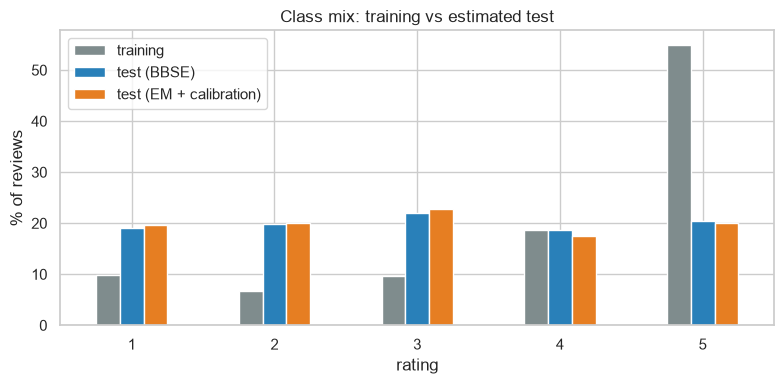

,training,test (BBSE),test (EM + calibration)
1,9.9,19.0,19.6
2,6.8,19.8,20.0
3,9.7,22.1,22.9
4,18.7,18.7,17.5
5,55.0,20.4,20.0


In [6]:
cal = ens.fit_bcts(Pe_a, ya)
src = cal(Pe_a).mean(0)
q_em = ens.em_mix(cal(Pe_t), src)

conf = confusion_matrix(ya, Pe_a.argmax(1) + 1, labels=range(1, 6), normalize="true")
mu = np.bincount(Pe_t.argmax(1), minlength=5) / len(Pe_t)
q_bbse, _ = nnls(conf.T, mu); q_bbse /= q_bbse.sum()
train_mix = np.bincount(ya, minlength=6)[1:] / len(ya)

mix = pd.DataFrame({"training": train_mix, "test (BBSE)": q_bbse, "test (EM + calibration)": q_em}, index=range(1, 6))
ax = (mix * 100).plot(kind="bar", figsize=(8, 4), rot=0, color=["#7f8c8d", "#2980b9", "#e67e22"])
ax.set(title="Class mix: training vs estimated test", xlabel="rating", ylabel="% of reviews")
plt.tight_layout(); plt.show()
(mix * 100).round(1)

**Story.** The training data is dominated by 5-star reviews (55 %), while both methods estimate that the test set has **about 20 % of each rating**. A model that learned the training mix will therefore over-predict 5 stars on the test set. The fix is to multiply the calibrated probabilities by *(estimated test mix / training mix)* before taking the maximum; this is the *prior correction* used for the final submission. The final predictions still over-predict 5 stars a little (22.8 % against an estimated 20.0 %) and under-predict 2 stars (18.0 % against 20.0 %), which is normal: the middle classes are the least separable.

## 3 · Honest evaluation under the test mix
We cannot score the test set, so we **resample validation B to the estimated test mix** (5 repetitions) and compare each model with the same calibration and correction pipeline. Weights and calibration were fitted on validation A only, so validation B is untouched.

In [7]:
rows = [ens.evaluate(n, Pa[i], Pb[i], Pt[i], ya, yb)[0] for i, n in enumerate(names)]
rows.append(ens.evaluate("ENSEMBLE", Pe_a, Pe_b, Pe_t, ya, yb)[0])
result = pd.DataFrame(rows).set_index("model").round(4)
result.T

model,classical,transformer,ENSEMBLE
log-loss (val B),0.7064,0.7171,0.6506
micro (uniform mix),0.5834,0.5926,0.6166
macro (uniform mix),0.5806,0.5882,0.6149
micro (test estimate mix),0.5877,0.5916,0.6124
macro (test estimate mix),0.5817,0.5863,0.6109


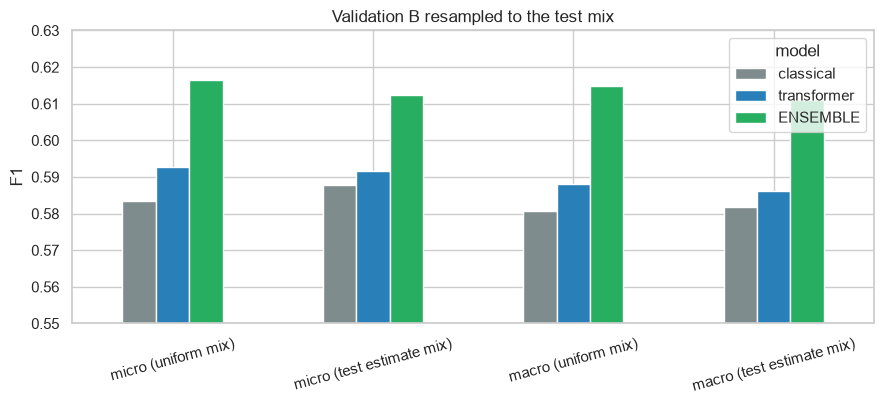

In [8]:
plot = result[["micro (uniform mix)", "micro (test estimate mix)", "macro (uniform mix)", "macro (test estimate mix)"]].T
ax = plot.plot(kind="bar", figsize=(9, 4.2), rot=15, color=["#7f8c8d", "#2980b9", "#27ae60"])
ax.set_ylim(0.55, 0.63); ax.set(title="Validation B resampled to the test mix", ylabel="F1")
plt.tight_layout(); plt.show()

**Story.** Each model alone reaches about **0.58-0.59 micro F1** under the balanced test mix. Their combination reaches **about 0.61-0.62**, roughly 2-3 points more, and the log-loss falls from about 0.71 to 0.65. The two models make different mistakes (one reads the words and the reviewer/product history, the other reads the whole sentence), so averaging their log-probabilities helps.

**Caveats we state openly.**
* These are *simulated* test scores. The real score depends on the label-shift assumption.
* The gap between the two single models (≈ 0.4 points) is within noise; the gain from combining them is not.

## 4 · Calibration (why the correction can be trusted)
Prior correction only works if the probabilities mean what they say. The plot compares confidence and observed accuracy on validation B, before and after bias-corrected temperature scaling.

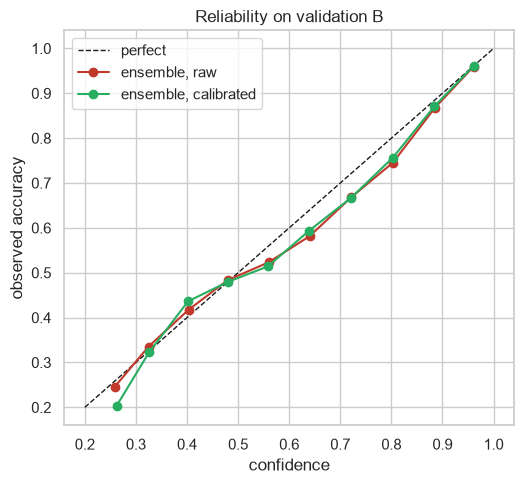

In [9]:
def reliability(P, y, bins=10):
    conf_, hit = P.max(1), (P.argmax(1) + 1 == y)
    edges = np.linspace(0.2, 1, bins + 1); idx = np.clip(np.digitize(conf_, edges) - 1, 0, bins - 1)
    xs = [conf_[idx == b].mean() for b in range(bins) if (idx == b).sum() > 50]
    ys = [hit[idx == b].mean() for b in range(bins) if (idx == b).sum() > 50]
    return xs, ys

fig, ax = plt.subplots(figsize=(5.4, 5))
ax.plot([0.2, 1], [0.2, 1], "k--", lw=1, label="perfect")
ax.plot(*reliability(Pe_b, yb), "o-", color="#c0392b", label="ensemble, raw")
ax.plot(*reliability(cal(Pe_b), yb), "o-", color="#27ae60", label="ensemble, calibrated")
ax.set(title="Reliability on validation B", xlabel="confidence", ylabel="observed accuracy"); ax.legend()
plt.tight_layout(); plt.show()

**Story.** The raw ensemble is already close to the diagonal: the fitted weights (sum below 1) already shrink the over-confident transformer, so calibration changes little. A small residual over-confidence remains between 0.5 and 0.8 confidence (observed accuracy 2-3 points below the stated confidence), and the lowest bin becomes slightly worse after calibration. We keep the calibration step because it is cheap and it makes the prior correction principled, but we do not claim that it is a large effect.

## 5 · The submission file
The final predictions are the maximum of *calibrated probability × (estimated test mix / training mix)*. We check that the file in `results/` is exactly what this pipeline produces and that it has the required format.

In [10]:
pred = ens.decide(cal(Pe_t), q_em, src)
final = pd.read_csv(RESULTS / "submission_2q.csv")
print("file in results/ identical to the pipeline output:", bool((final["predicted"].to_numpy() == pred).all()))
print("columns:", list(final.columns), "| rows:", len(final), "| values:", sorted(final["predicted"].unique()))
mixes = pd.DataFrame({"estimated true test mix": q_em,
                      "final predictions": np.bincount(pred, minlength=6)[1:] / len(pred),
                      "no correction (argmax of raw)": np.bincount(Pe_t.argmax(1) + 1, minlength=6)[1:] / len(pred)}, index=range(1, 6))
(mixes * 100).round(1)

file in results/ identical to the pipeline output: True
columns: ['predicted'] | rows: 20000 | values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


,estimated true test mix,final predictions,no correction (argmax of raw)
1,19.6,20.3,25.9
2,20.0,18.0,9.2
3,22.9,22.8,16.8
4,17.5,16.0,16.9
5,20.0,22.8,31.2


## Summary

| Question | Answer |
|----------|--------|
| Which model? | An **ensemble** of a classical TF-IDF model and a fine-tuned transformer |
| Why an ensemble? | Different mistakes: ≈ +2-3 micro F1 and lower log-loss than either model alone (simulated test mix) |
| Why not balance the training data? | The decision is made at prediction time: calibrated probabilities are re-weighted to the estimated test mix |
| What is the expected test score? | About 0.6 micro F1 (simulation), **not** the 0.72-0.74 seen at the training mix |
| What can go wrong? | The label-shift assumption; the real test score is unknown until the organisers score it |